# Ember Malaware

## Setup

Imports used throughout the notebook.

In [13]:
import pandas as pd                # tables (DataFrame) + CSV loading
import numpy as np                 # numeric arrays / math
import matplotlib.pyplot as plt    # base plotting library
import seaborn as sns              # nicer statistical charts built on top of matplotlib
from scipy import stats
import math

# scikit-learn building blocks:
from sklearn.model_selection import train_test_split              # split data into train / test
from sklearn import metrics
from sklearn.preprocessing import StandardScaler                  # standardize features (mean 0, std 1)
from sklearn.linear_model import LogisticRegression               # the classification model used here
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, recall_score

## 1. Data overview

Load the dataset and inspect its shape, columns and summary statistics.

In [14]:
df = pd.read_csv('./ember_malware_features.csv')
df.shape

(199956, 66)

## 2. Correlations

All 66 columns are numeric, so Pearson correlations can be computed directly. A full 66×66 heatmap would be unreadable, so we look at what matters for a classifier: first how each feature relates to the target `is_malware`, then a zoom on the strongest ones (which also exposes redundant features).

> Note: several features are very skewed (see `describe` above), which weakens *linear* correlation. For a logistic regression, apply `np.log1p()` before standardizing.

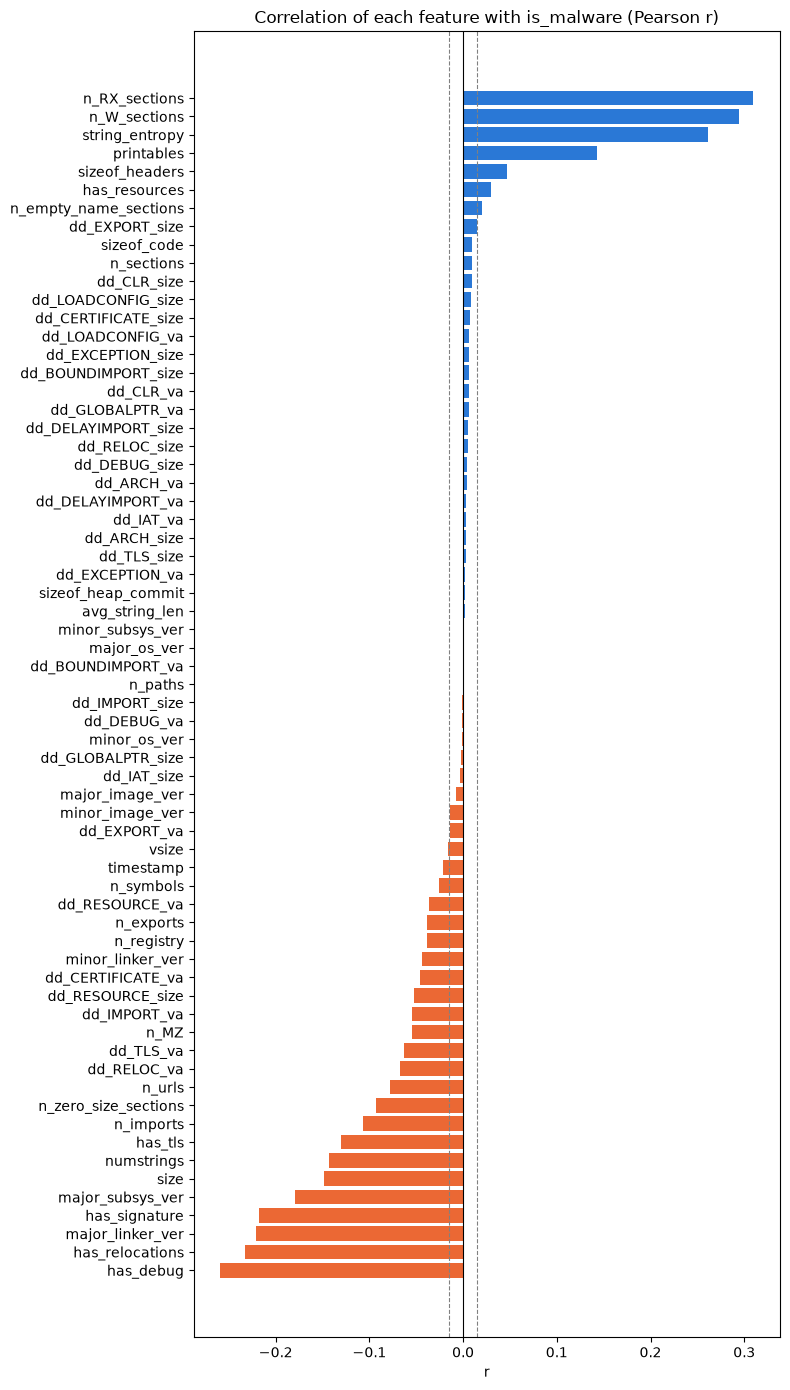

In [15]:
corr_target = df.corr(numeric_only=True)['is_malware'].drop('is_malware').sort_values()

colors = ['#2a78d6' if r > 0 else '#eb6834' for r in corr_target]   # blue = positive, orange = negative
plt.figure(figsize=(8, 14))
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.axvline(-0.015, color='gray', linewidth=0.8, linestyle='--')
plt.axvline(0.015, color='gray', linewidth=0.8, linestyle='--')
plt.title('Correlation of each feature with is_malware (Pearson r)')
plt.xlabel('r')
plt.tight_layout()
plt.show()

In [16]:
def getCorrelation(elem):
    r, _ = stats.pointbiserialr(df["is_malware"], df[elem])
    return r

correlations = [getCorrelation(elem) for elem in df.columns]
filter_columns = [df.columns[i] for i in range(len(correlations)) if np.abs(correlations[i]) > 0.015]
print(f"Columns on both sides: {len(df.columns)} - {len(filter_columns)}")
df_filter = df[filter_columns]

Columns on both sides: 66 - 33


### What the filter keeps — in plain words

The cell above measures how strongly each column moves together with the label `is_malware`
(*point-biserial correlation* = Pearson's **r** between a 0/1 column and a numeric one), and keeps
only the columns where that link is stronger than **0.015** in either direction. Those are the clues
that lean toward "malware" or "safe". Everything that barely moves with the label is dropped.

**33 columns survive: 32 clues + the label itself** (`is_malware`, which correlates perfectly with
itself and is kept as the answer we want to predict). The split is lopsided — **8** clues lean
malware (r > 0) and **24** lean safe (r < 0).

**Clues more typical of MALWARE (r > 0) — 8:**
- `n_RX_sections` (+0.31) — number of blocks that are both readable and runnable; more of them → more suspicious.
- `n_W_sections` (+0.29) — number of blocks the program can rewrite while running; a sign of code that unpacks/decrypts itself.
- `string_entropy` (+0.26) — how "scrambled/random" the readable text looks; encrypted or compressed content (common in malware) looks more random.
- `printables` (+0.14) — overall amount of readable characters, slightly higher.
- `sizeof_headers` (+0.05) — declared header size; weak lean toward malware.
- `has_resources` (+0.03) — carries a resource section; very weak lean.
- `n_empty_name_sections` (+0.02) — sections with blank names; very weak lean.
- `dd_EXPORT_size` (+0.02) — size of the export data directory; very weak lean (right at the threshold).

**Clues more typical of SAFE files (r < 0) — 24:**
- `has_debug` (−0.26) — carries debugging info; legitimate software keeps it more often.
- `has_relocations` (−0.23) — has a relocation table; more common in legitimate software.
- `major_linker_ver` (−0.22) — version of the tool that built the program; benign software tends to use newer ones.
- `has_signature` (−0.22) — is digitally signed by a verified publisher (safe files far more often: ~25% vs ~9%).
- `major_subsys_ver` (−0.18) — declared interface (GUI/console) version; older values lean malware.
- `size` (−0.15) — file size on disk; malware here tends to be smaller.
- `numstrings` (−0.14) — count of readable text snippets; fewer in malware (packed files expose less text).
- `has_tls` (−0.13) — runs some code before the main program starts; in this dataset, slightly more common in safe files.
- `n_imports` (−0.11) — number of functions borrowed from Windows libraries; legitimate software declares more.
- `n_zero_size_sections` (−0.09) — count of empty sections; weak lean toward safe.
- `n_urls` (−0.08) — URLs found in the file; weak lean toward safe.
- `dd_RELOC_va` (−0.07) — address of the relocation directory; weak (tracks `has_relocations`).
- `dd_TLS_va` (−0.06) — address of the TLS directory; weak (tracks `has_tls`).
- `n_MZ` (−0.06) — count of embedded `MZ` headers; weak lean.
- `dd_IMPORT_va` (−0.06) — address of the import directory; weak lean.
- `dd_RESOURCE_size` (−0.05) — size of the resource directory; weak lean.
- `dd_CERTIFICATE_va` (−0.05) — address of the certificate directory; weak (tracks `has_signature`).
- `minor_linker_ver` (−0.04) — minor linker version; weak lean.
- `n_registry` (−0.04) — registry references; weak lean.
- `n_exports` (−0.04) — number of exported functions; weak lean.
- `dd_RESOURCE_va` (−0.04) — address of the resource directory; weak lean.
- `n_symbols` (−0.03) — symbol-table entries; weak lean.
- `timestamp` (−0.02) — build timestamp; very weak lean.
- `vsize` (−0.02) — virtual size; very weak lean (right at the threshold).

**Target:**
- `is_malware` (1.00) — the answer itself: 0 = safe, 1 = malware.

> Note: many of the weak negatives are `dd_*_va` address directories that simply track their matching flag
> (e.g. `dd_RELOC_va` ↔ `has_relocations`), so they add little independent signal — see the heatmap below.

dataset length: 66, filtered dataset length: 30


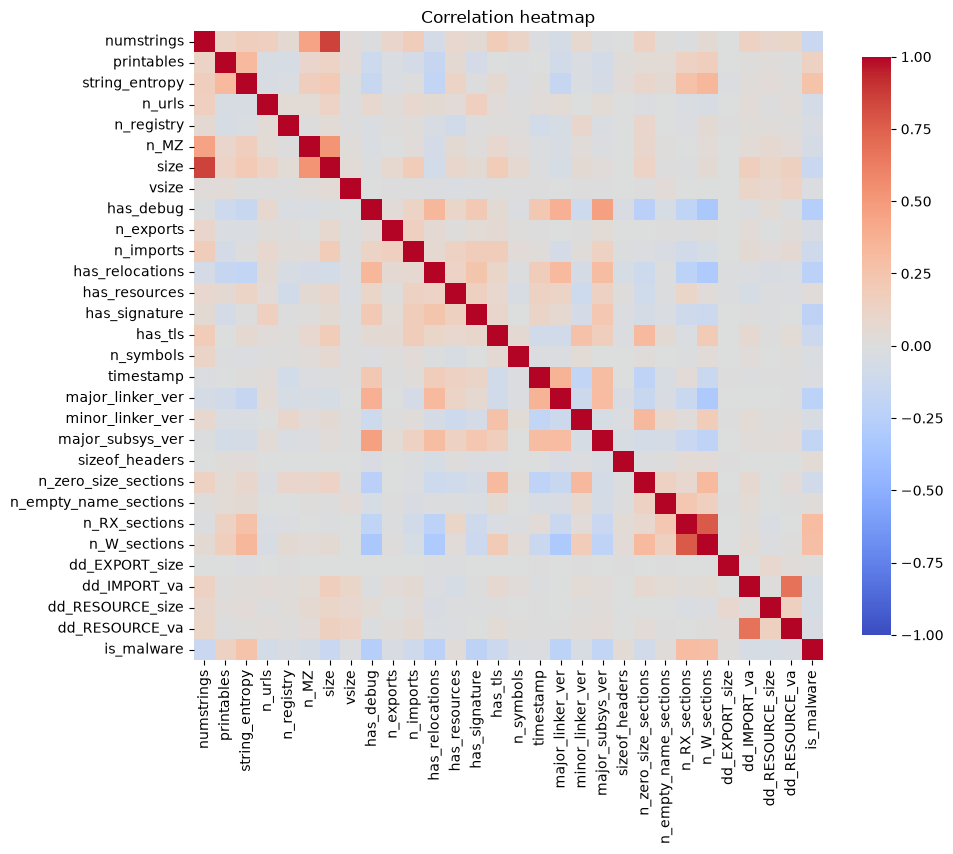

In [17]:
df_filter = df_filter.drop(columns=['dd_RELOC_va', 'dd_TLS_va', 'dd_CERTIFICATE_va'])
# This drop of columns above is done while we are writing the presentation, so it won't be shown. Doesn't change much results.
# We are dropping those columns as they are kind of duplicated by has_relocations, has_tls and has_signature 
print(f"dataset length: {len(df.columns)}, filtered dataset length: {len(df_filter.columns)}")
plt.figure(figsize=(10, 9))
sns.heatmap(df_filter.corr(), annot=False, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

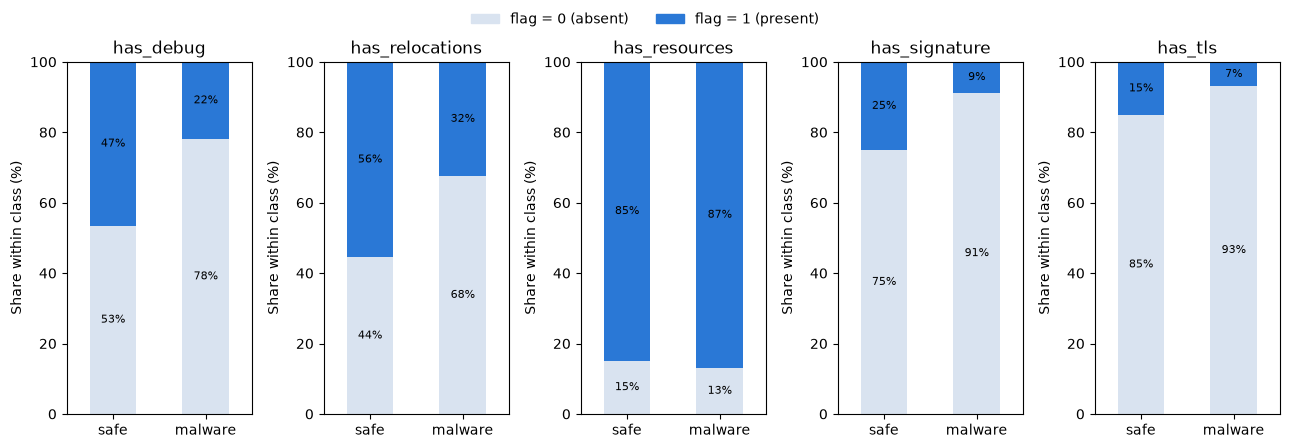

In [18]:
binary_cols = [c for c in df_filter.columns if df_filter[c].nunique(dropna=True) == 2]
binary_cols.remove('is_malware')

# Within each class (safe / malware), show how files split between flag absent (0) and
# present (1), stacked so each bar sums to 100%.
flag_colors = {0: '#d9e3f0', 1: '#2a78d6'}   # 0 = flag absent (light), 1 = flag present (blue)
class_labels = {0: 'safe', 1: 'malware'}

fig, axes = plt.subplots(1, len(binary_cols), figsize=(2.6 * len(binary_cols), 4.5))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, binary_cols):
    ct = pd.crosstab(df_filter['is_malware'], df_filter[col], normalize='index') * 100
    ct = ct.rename(index=class_labels)
    ct.plot(kind='bar', stacked=True, ax=ax, rot=0, legend=False,
            color=[flag_colors[c] for c in ct.columns])
    for container in ax.containers:
        ax.bar_label(container,
                     labels=[f'{v:.0f}%' if v > 4 else '' for v in container.datavalues],
                     label_type='center', fontsize=8)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Share within class (%)')
    ax.set_ylim(0, 100)

handles = [plt.Rectangle((0, 0), 1, 1, color=flag_colors[f]) for f in (0, 1)]
fig.legend(handles, ['flag = 0 (absent)', 'flag = 1 (present)'],
           loc='upper center', ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

5 small-count columns: ['n_registry', 'major_subsys_ver', 'n_zero_size_sections', 'n_RX_sections', 'n_W_sections']


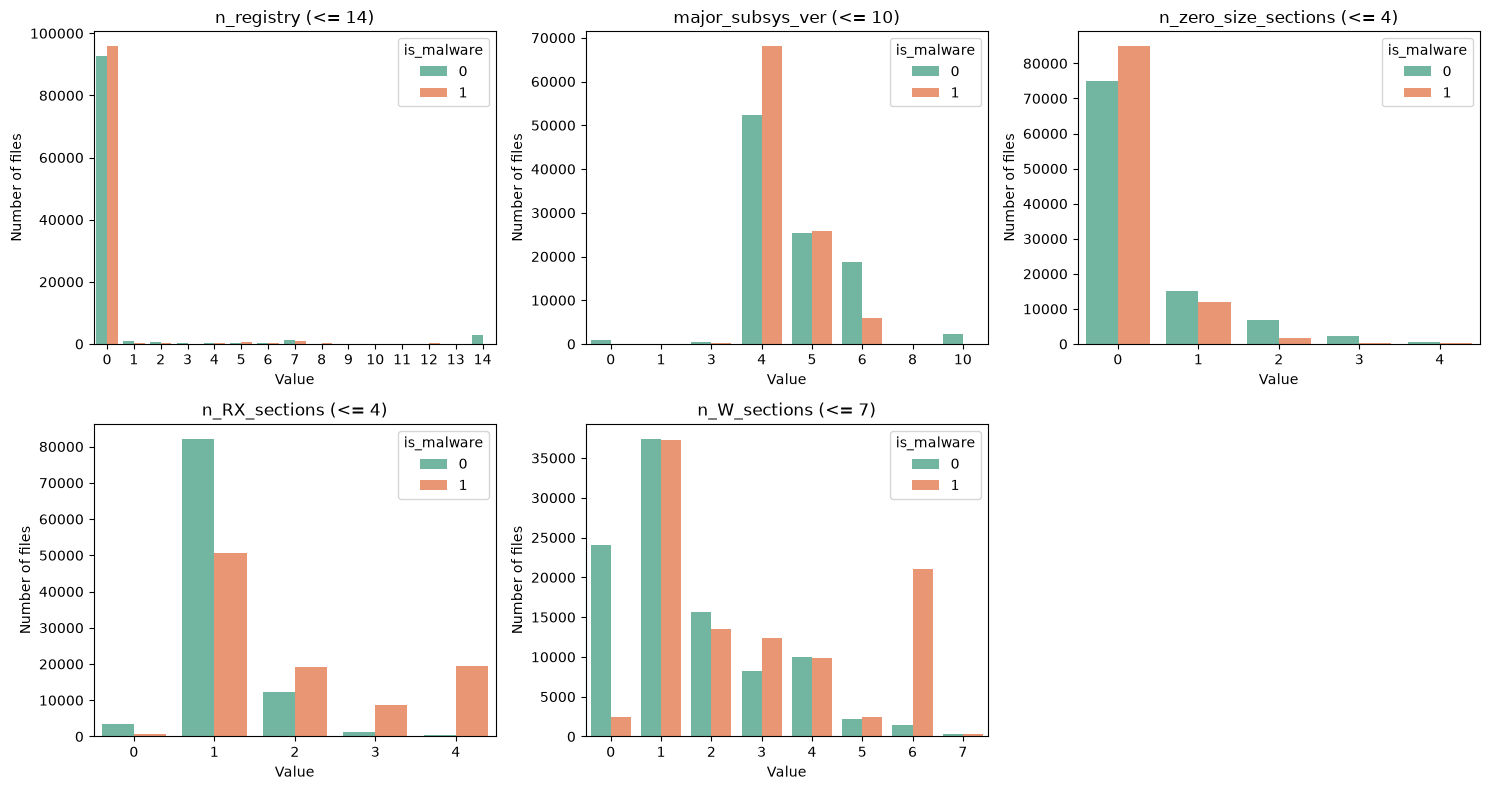

In [19]:
# Group columns by the "type" of values they hold and keep the small discrete "counts"
# (like n_W_sections) — the only ones where a per-value countplot/lineplot is meaningful.
# The huge-valued continuous columns (size, timestamp, dd_*_va, entropies...) are excluded,
# and the binary 0/1 flags are already covered by cell above.
# Source columns from df_filter (the 33 selected features the model trains on), not df.
SMALL_VALUE_MAX = 15

binary_cols = [c for c in df_filter.columns if df_filter[c].nunique() == 2]
count_cols = [
    c for c in df_filter.columns
    if c != "is_malware"
    and c not in binary_cols
    and df_filter[c].dtype.kind in "iu"                    # integer columns only
    and df_filter[c].quantile(0.99) < SMALL_VALUE_MAX      # values stay small
    and df_filter[c].value_counts(normalize=True).iloc[0] < 0.95  # not near-constant (drops all-zero columns)
]
print(f"{len(count_cols)} small-count columns:", count_cols)

# One countplot per column: counts per value, split by is_malware
ncols = 3
nrows = math.ceil(len(count_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, count_cols):
    cap = int(df_filter[col].quantile(0.99))     # drop the long tail, like the <= 6 in the original
    sns.countplot(data=df_filter[df_filter[col] <= cap], x=col, hue="is_malware", palette="Set2", ax=ax)
    ax.set_title(f"{col} (<= {cap})")
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of files")
for ax in axes[len(count_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()


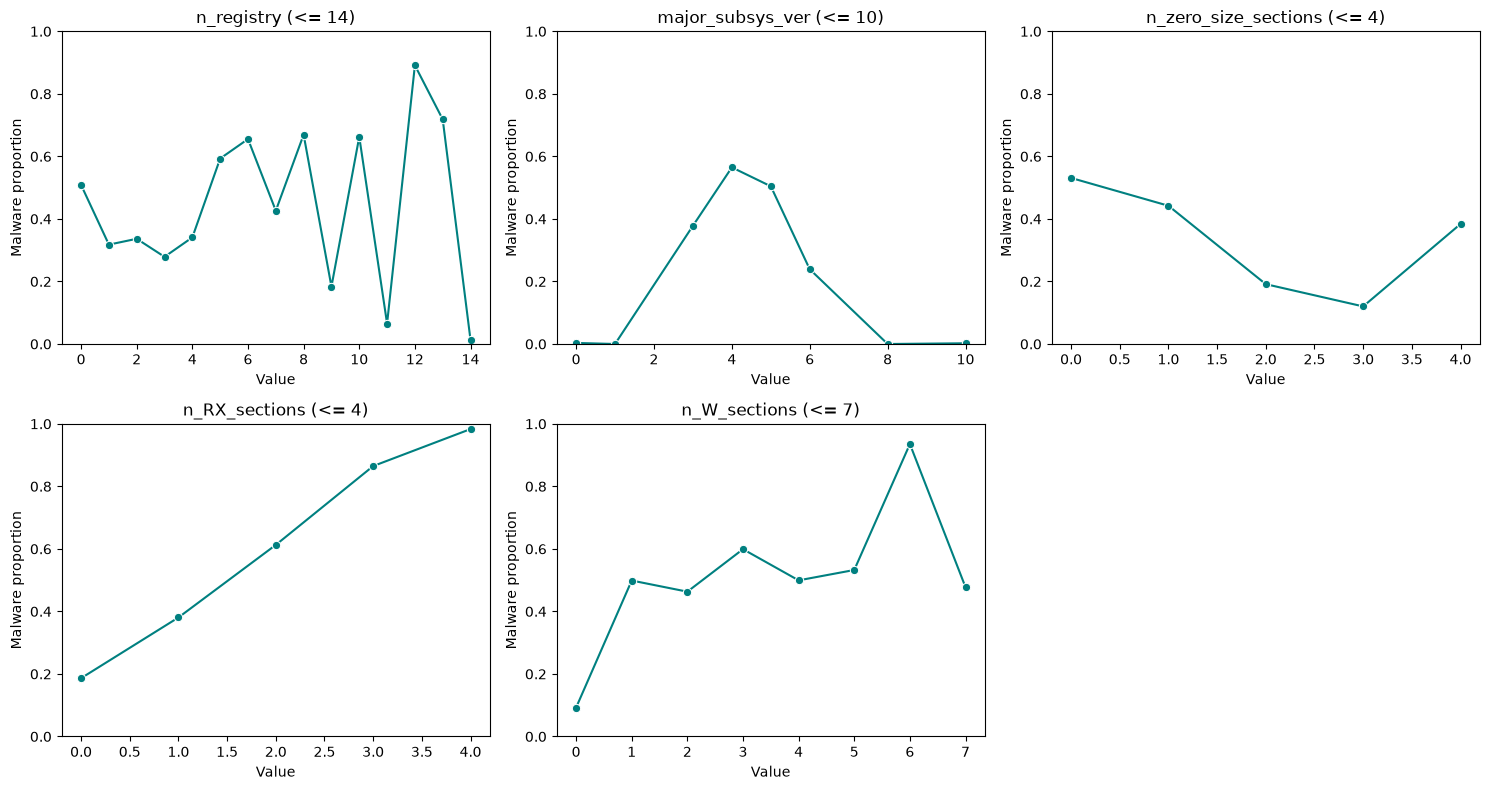

In [20]:
# Reuses count_cols from cell above. One lineplot per column: malware proportion per value.
ncols = 3
nrows = math.ceil(len(count_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, count_cols):
    cap = int(df_filter[col].quantile(0.99))
    sns.lineplot(
        data=df_filter[df_filter[col] <= cap],
        x=col,
        y="is_malware",
        estimator="mean",
        errorbar=None,
        marker="o",
        color="teal",
        ax=ax,
    )
    ax.set_title(f"{col} (<= {cap})")
    ax.set_xlabel("Value")
    ax.set_ylabel("Malware proportion")
    ax.set_ylim(0, 1)
for ax in axes[len(count_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()


# Tests results of the cell under based on different settings 

## Without `np.log1` applied, accuracy scores:
5. with correlations above 0: Train -> 0.7735, Test -> 0.7763")
4. with correlations above 0.025: Train -> 0.7681, Test -> 0.7698")
3. with correlations above 0.05: Train -> 0.7664, Test -> 0.7680")
1. with correlations above 0.1: Train -> 0.7417, Test -> 0.7452")
2. with correlations above 0.15: Train -> 0.6933, Test -> 0.6933")

## With `np.log1` applied, accuracy scores:
1. with correlations above 0: Train -> 0.8331, Test -> 0.8331")
2. with correlations above 0.025: Train -> 0.7858, Test -> 0.7860")
2. with correlations above 0.05: Train -> 0.7663, Test -> 0.7671")
3. with correlations above 0.1: Train -> 0.7340, Test -> 0.7342")

In [21]:
features = df_filter.columns.drop('is_malware')
y = df_filter.loc[:, 'is_malware']
X = df_filter.loc[:, features]

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=0)

X_train = np.log1p(X_train)
X_test = np.log1p(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, y_train)
clf.predict_proba(X_test)

print("Train score: ", clf.score(X_train, y_train))
print("Test score: ", clf.score(X_test, y_test))
y.value_counts()

Train score:  0.7649158560676153
Test score:  0.7667033406681336


is_malware
0    99985
1    99971
Name: count, dtype: int64

--- train set ---
P(malware) first 5 : [0.567 0.94  0.528 0.145 0.394]
label  @ 0.25      : [1 1 1 0 1]
label  @ 0.50      : [1 1 1 0 0] (what .predict() would give)


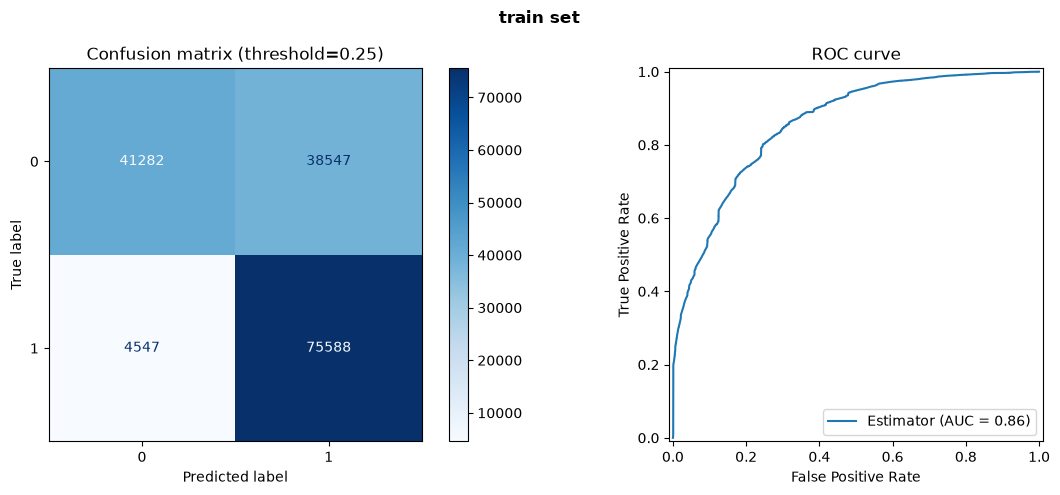

accuracy-score on train set : 0.7306018854242204
Recall on train set        : 0.9432582517002558
Roc Curve is drawn on 48051 thresholds
--- test set ---
P(malware) first 5 : [0.022 0.352 0.079 0.216 0.98 ]
label  @ 0.25      : [0 1 0 0 1]
label  @ 0.50      : [0 0 0 0 1] (what .predict() would give)


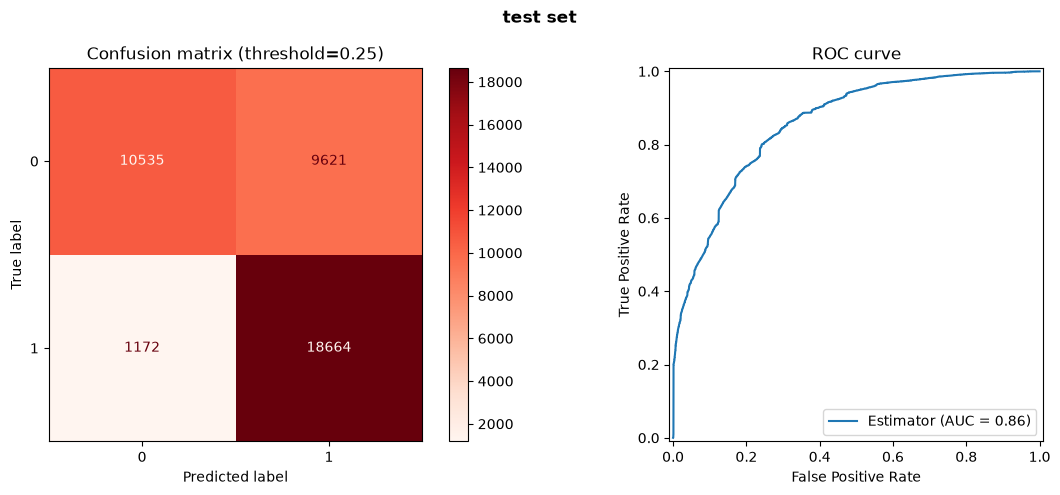

accuracy-score on test set : 0.7301210242048409
Recall on test set        : 0.9409155071587013
Roc Curve is drawn on 11624 thresholds


In [22]:
threshold = 0.25  # lower than the default 0.5 -> flags more files as malware -> higher recall

for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    proba = clf.predict_proba(X)[:, 1]            # P(malware) for every file, between 0 and 1
    y_pred = (proba >= threshold).astype(int)     # draw the cutoff by hand -> 0/1 labels

    # Show the probability -> label step on the first 5 files
    print(f"--- {name} set ---")
    print("P(malware) first 5 :", np.round(proba[:5], 3))
    print("label  @ 0.25      :", y_pred[:5])
    print("label  @ 0.50      :", (proba[:5] >= 0.5).astype(int), "(what .predict() would give)")

    # One figure per set: confusion matrix (left) + ROC curve (right)
    fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

    ConfusionMatrixDisplay.from_predictions(y, y_pred, cmap=plt.cm.Blues if name == 'train' else plt.cm.Reds, ax=ax_cm)
    ax_cm.set_title(f"Confusion matrix (threshold={threshold})")

    fpr, tpr, thresholds = metrics.roc_curve(y, proba)
    roc_auc = metrics.auc(fpr, tpr)
    metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, name='Estimator').plot(ax=ax_roc)
    ax_roc.set_title("ROC curve")

    fig.suptitle(f"{name} set", fontweight='bold')
    fig.tight_layout()
    plt.show()

    print(f"accuracy-score on {name} set : {accuracy_score(y, y_pred)}")
    print(f"Recall on {name} set        : {recall_score(y, y_pred)}")
    print(f"Roc Curve is drawn on {len(thresholds)} thresholds")


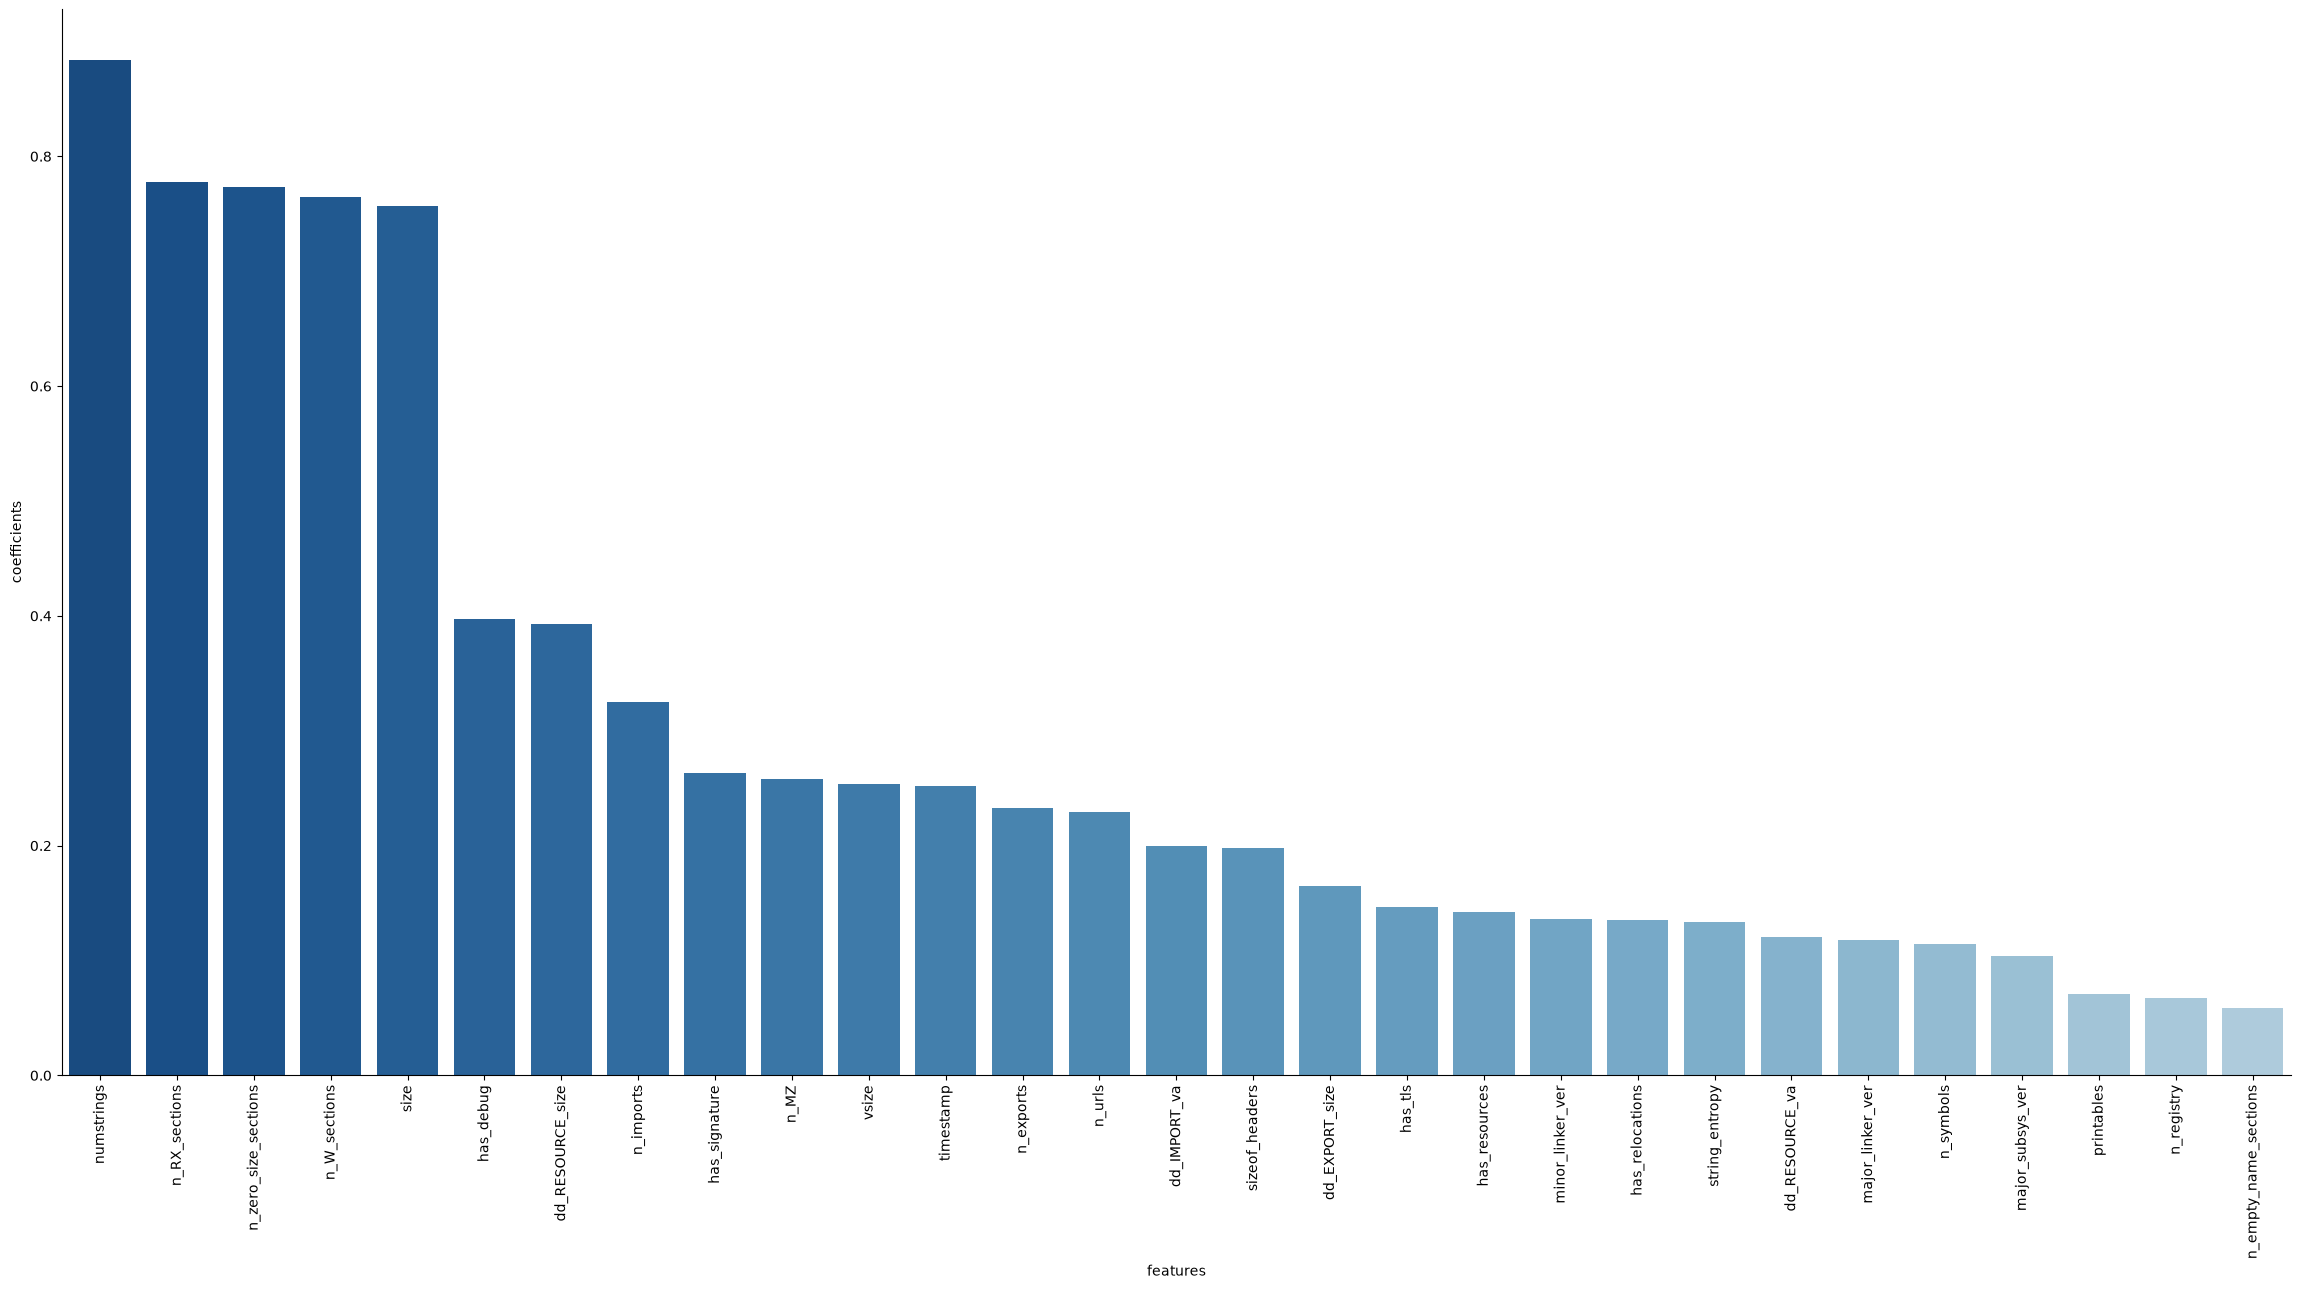

In [23]:
feature_importance = pd.DataFrame({
    "features": features,
    "coefficients":clf.coef_.squeeze()
})


feature_importance["coefficients"] = feature_importance["coefficients"].abs()
fi_sorted = feature_importance.sort_values(by="coefficients", ascending=False)

ramp = plt.cm.Blues(np.linspace(0.9, 0.35, len(fi_sorted)))
bar_colors = dict(zip(fi_sorted["features"], ramp))

sns.catplot(x="features",
            y="coefficients",
            data=fi_sorted,
            kind="bar",
            hue="features",
            palette=bar_colors,
            legend=False,
            height=13,   # (inches)
            aspect=16/9) # Resize graph

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

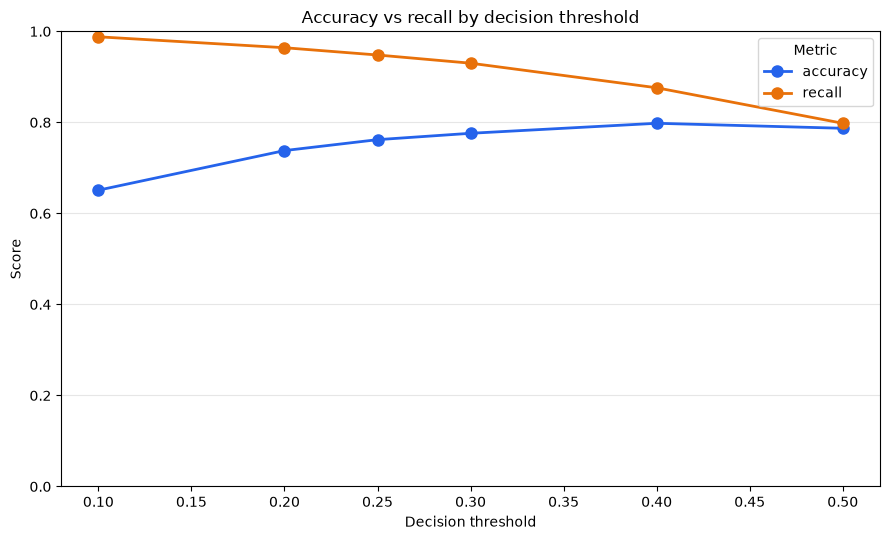

In [24]:
tac = pd.DataFrame({
    "threshold": [0.1, 0.2, 0.25, 0.3, 0.4, 0.5],
    "accuracy": [0.651, 0.738, 0.762, 0.776, 0.798, 0.787],
    "recall": [0.988, 0.964, 0.948, 0.930, 0.876, 0.798]
})

colors = {"accuracy": "#2563eb", "recall": "#e8710a"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for metric in ["accuracy", "recall"]:
    ax.plot(tac["threshold"], tac[metric],
            marker="o", markersize=8, linewidth=2,
            color=colors[metric], label=metric)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Accuracy vs recall by decision threshold")
ax.set_ylim(0, 1)
ax.grid(axis="y", color="0.9", linewidth=0.8)
ax.legend(title="Metric")
plt.tight_layout()
plt.show()
